# Notebook 2: Eksperimen Baseline — 2D CNN dengan Fitur MFCC

Eksperimen pertama sebagai baseline menggunakan arsitektur 2D CNN murni dengan input fitur MFCC (40x130x1).

MFCC dipilih sebagai baseline karena merupakan fitur audio paling umum di penelitian klasifikasi suara. Tujuan eksperimen ini adalah mengukur seberapa jauh MFCC mampu membedakan 8 maqam tilawah ketika diuji pada data yang benar-benar belum pernah dilihat model (test set murni tanpa leakage).

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

# 1. Kunci Random Seed agar eksperimen 100% Reproducible
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Cari otomatis file maqam_2d_dataset.npz di /kaggle/input (Output dari Notebook 1)
DATASET_PATH = None
for root, _, files in os.walk("/kaggle/input"):
    if "maqam_2d_dataset.npz" in files:
        DATASET_PATH = os.path.join(root, "maqam_2d_dataset.npz")
        break

if DATASET_PATH is None:
    raise FileNotFoundError("File maqam_2d_dataset.npz tidak ditemukan! Pastikan Notebook 1 sudah ditambahkan via '+ Add Input' -> 'Kernel Output'.")

print(f"[INFO] Memuat dataset fitur dari: {DATASET_PATH}")
data = np.load(DATASET_PATH, allow_pickle=True)

# Tambahkan dimensi channel (Height, Width, Channel) -> (130, 13, 1)
X_train = data['X_train_mfcc'][..., np.newaxis]
y_train = data['y_train']

X_val   = data['X_val_mfcc'][..., np.newaxis]
y_val   = data['y_val']

X_test  = data['X_test_mfcc'][..., np.newaxis]
y_test  = data['y_test']

# Konversi eksplisit class_names ke list string Python murni
CLASS_NAMES = [str(c) for c in data['class_names']]
NUM_CLASSES = len(CLASS_NAMES)

print(f"[INFO] Kelas Maqam ({NUM_CLASSES}) : {CLASS_NAMES}")
print(f"[INFO] X_train shape    : {X_train.shape} | y_train shape: {y_train.shape}")
print(f"[INFO] X_val shape      : {X_val.shape}   | y_val shape  : {y_val.shape}")
print(f"[INFO] X_test shape     : {X_test.shape}  | y_test shape : {y_test.shape}")


[INFO] Memuat dataset fitur dari: /kaggle/input/notebooks/ahmadfikr/01-preprocessing-extraction/maqam_2d_dataset.npz
[INFO] Kelas Maqam (8) : ['Ajam', 'Bayati', 'Hijaz', 'Kurdi', 'Nahawand', 'Rast', 'Saba', 'Sikah']
[INFO] X_train shape    : (6158, 130, 13, 1) | y_train shape: (6158,)
[INFO] X_val shape      : (385, 130, 13, 1)   | y_val shape  : (385,)
[INFO] X_test shape     : (385, 130, 13, 1)  | y_test shape : (385,)


### 2. Membangun Arsitektur 2D CNN (Baseline MFCC)


In [2]:
def build_cnn_2d_mfcc(input_shape, num_classes=8, l2_reg=1e-4, name="CNN_2D_MFCC"):
    l2 = regularizers.l2(l2_reg)
    inputs = layers.Input(shape=input_shape, name="input_mfcc")
    
    # Blok Konvolusi 1
    x = layers.Conv2D(32, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv1")(inputs)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.Activation('relu', name="relu1")(x)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)
    x = layers.SpatialDropout2D(0.20, name="spatial_drop1")(x)
    
    # Blok Konvolusi 2
    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv2")(x)
    x = layers.BatchNormalization(name="bn2")(x)
    x = layers.Activation('relu', name="relu2")(x)
    x = layers.MaxPooling2D((2, 2), name="pool2")(x)
    x = layers.SpatialDropout2D(0.25, name="spatial_drop2")(x)
    
    # Blok Konvolusi 3 (Pooling pada dimensi waktu saja untuk menjaga koefisien spektral)
    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv3")(x)
    x = layers.BatchNormalization(name="bn3")(x)
    x = layers.Activation('relu', name="relu3")(x)
    x = layers.MaxPooling2D((2, 1), name="pool3")(x)
    x = layers.SpatialDropout2D(0.30, name="spatial_drop3")(x)
    
    # Global Average Pooling & Dense Classifier Head
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(128, use_bias=False, kernel_regularizer=l2, name="dense1")(x)
    x = layers.BatchNormalization(name="bn_dense")(x)
    x = layers.Activation('relu', name="relu_dense")(x)
    x = layers.Dropout(0.40, name="dropout_dense")(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="output_maqam")(x)
    
    model = models.Model(inputs=inputs, outputs=outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_cnn_2d_mfcc(input_shape=X_train.shape[1:], num_classes=NUM_CLASSES)
model.summary()


Model: "CNN_2D_MFCC"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_mfcc (InputLayer)         │ (None, 130, 13, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 130, 13, 32)    │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 130, 13, 32)    │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 130, 13, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 65, 6, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop1                   │ (None, 65, 6, 32)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 65, 6, 64)      │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 65, 6, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 65, 6, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 3, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop2                   │ (None, 32, 3, 64)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 3, 128)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 3, 128)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 3, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 3, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop3                   │ (None, 16, 3, 128)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_dense (BatchNormalization)   │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_dense (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_maqam (Dense)            │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,272 (434.66 KB)

 Trainable params: 110,568 (431.91 KB)

 Non-trainable params: 704 (2.75 KB)

### 3. Pelatihan Model dengan Callbacks Terstruktur
Proses pelatihan menggunakan strategi adaptif untuk mengoptimalkan konvergensi dan mencegah overfitting:
- **`ModelCheckpoint`**: Menyimpan bobot model terbaik (`model_exp1_mfcc.keras`) berdasarkan nilai `val_loss` terendah.
- **`ReduceLROnPlateau`**: Mengurangi learning rate sebesar 50% jika `val_loss` mengalami stagnasi selama 5 epoch.
- **`EarlyStopping`**: Menghentikan training jika tidak ada penurunan `val_loss` selama 12 epoch berturut-turut, serta otomatis mengembalikan bobot terbaik (*restore_best_weights*).


In [3]:
BEST_MODEL_PATH = "/kaggle/working/model_exp1_mfcc.keras"

cb_list = [
    callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS = 80
BATCH_SIZE = 32

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=cb_list,
    verbose=1
)


Epoch 1/80
193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1639 - loss: 2.4311
Epoch 1: val_loss improved from None to 1.87283, saving model to /kaggle/working/model_exp1_mfcc.keras

Epoch 1: finished saving model to /kaggle/working/model_exp1_mfcc.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - accuracy: 0.1936 - loss: 2.2934 - val_accuracy: 0.3195 - val_loss: 1.8728 - learning_rate: 0.0010
Epoch 2/80
190/193 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2461 - loss: 2.0527
Epoch 2: val_loss improved from 1.87283 to 1.72795, saving model to /kaggle/working/model_exp1_mfcc.keras

Epoch 2: finished saving model to /kaggle/working/model_exp1_mfcc.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2572 - loss: 2.0292 - val_accuracy: 0.3740 - val_loss: 1.7280 - learning_rate: 0.0010
Epoch 3/80
183/193 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2686 - loss: 1.9726
Epoch 3: val_loss improved from 1.72795 to 1.72716, saving model to /kaggle/working/model_exp1_mfcc.ke

### 4. Visualisasi Kurva Loss & Accuracy
Evaluasi stabilitas proses konvergensi model pada setiap epoch untuk menganalisis apakah model mengalami underfitting, overfitting, atau generalisasi optimal.


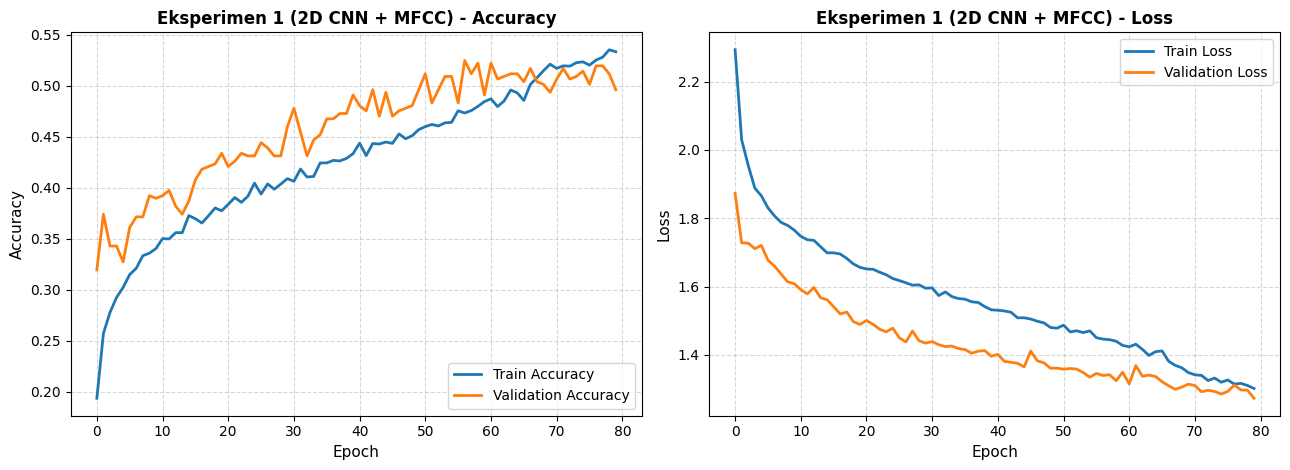

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Plot Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='#1f77b4', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ff7f0e', linewidth=2)
axes[0].set_title('Eksperimen 1 (2D CNN + MFCC) - Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Accuracy', fontsize=11)
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Plot Loss
axes[1].plot(history.history['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=2)
axes[1].set_title('Eksperimen 1 (2D CNN + MFCC) - Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Loss', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("/kaggle/working/kurva_training_exp1_mfcc.png", dpi=300)
plt.show()


### 5. Evaluasi Komprehensif pada Test Set (Data Uji Murni)
Pengujian performa model terbaik terhadap data uji murni `X_test` (385 sampel audio yang belum pernah dilihat model pada tahap training maupun validasi).


HASIL EVALUASI EKSPERIMEN 1: 2D CNN + MFCC (TEST SET)
Test Accuracy         : 51.69%
Macro Precision       : 54.98%
Macro Recall          : 47.17%
Macro F1-Score        : 47.79%
Weighted F1-Score     : 50.16%

Classification Report per Kelas Maqam:

              precision    recall  f1-score   support

        Ajam     0.4068    0.4615    0.4324        52
      Bayati     0.4643    0.3714    0.4127        35
       Hijaz     0.4355    0.6750    0.5294        80
       Kurdi     0.5000    0.0882    0.1500        34
    Nahawand     0.8125    0.3714    0.5098        35
        Rast     0.5323    0.6111    0.5690        54
        Saba     0.8627    0.8462    0.8544        52
       Sikah     0.3846    0.3488    0.3659        43

    accuracy                         0.5169       385
   macro avg     0.5498    0.4717    0.4779       385
weighted avg     0.5398    0.5169    0.5016       385



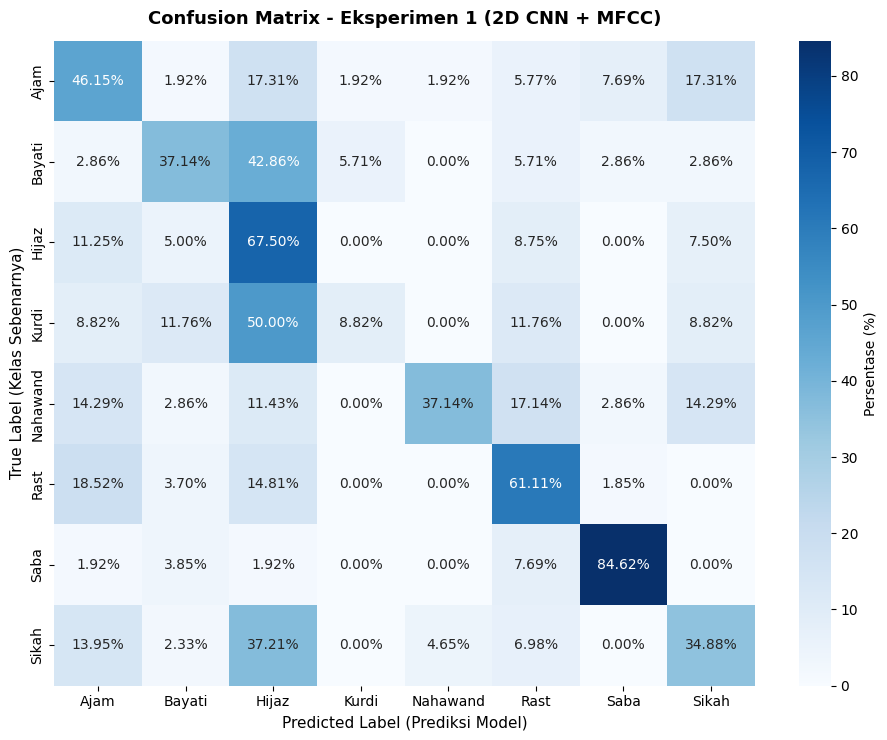

[SUKSES] Hasil evaluasi & model terbaik Eksperimen 1 berhasil disimpan.


In [5]:
# Muat model terbaik yang disimpan selama proses pelatihan
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

# Prediksi probabilitas dan label kelas pada Test Set
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Hitung metrik evaluasi klasifikasi
test_acc = accuracy_score(y_test, y_pred)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)

print("=" * 70)
print("HASIL EVALUASI EKSPERIMEN 1: 2D CNN + MFCC (TEST SET)")
print("=" * 70)
print(f"Test Accuracy         : {test_acc * 100:.2f}%")
print(f"Macro Precision       : {prec_macro * 100:.2f}%")
print(f"Macro Recall          : {rec_macro * 100:.2f}%")
print(f"Macro F1-Score        : {f1_macro * 100:.2f}%")
print(f"Weighted F1-Score     : {f1_weighted * 100:.2f}%")
print("=" * 70)
print("\nClassification Report per Kelas Maqam:\n")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

# Confusion Matrix Persentase per True Label (Baris)
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(9.5, 7.5))
sns.heatmap(
    cm_percent, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar_kws={'label': 'Persentase (%)'}
)
for t in plt.gca().texts:
    t.set_text(t.get_text() + "%")

plt.title("Confusion Matrix - Eksperimen 1 (2D CNN + MFCC)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Label (Prediksi Model)", fontsize=11)
plt.ylabel("True Label (Kelas Sebenarnya)", fontsize=11)
plt.tight_layout()
plt.savefig("/kaggle/working/cm_exp1_mfcc.png", dpi=300)
plt.show()

# Simpan hasil evaluasi ke file .npz untuk agregasi komparasi pada Notebook 5
np.savez(
    "/kaggle/working/eval_exp1_mfcc.npz",
    experiment_name="Exp 1: 2D CNN (MFCC)",
    test_acc=float(test_acc),
    prec_macro=float(prec_macro),
    rec_macro=float(rec_macro),
    f1_macro=float(f1_macro),
    prec_weighted=float(prec_weighted),
    rec_weighted=float(rec_weighted),
    f1_weighted=float(f1_weighted),
    y_test=y_test,
    y_pred=y_pred,
    class_names=np.array(CLASS_NAMES, dtype=object),
    history_acc=history.history['accuracy'],
    history_val_acc=history.history['val_accuracy'],
    history_loss=history.history['loss'],
    history_val_loss=history.history['val_loss']
)
print("[SUKSES] Hasil evaluasi & model terbaik Eksperimen 1 berhasil disimpan.")
